# CSCE 5218 Assignment 11: nanoGPT

**Group 7 Member 2**

For my part of the group assignment, I used the Tiny Shakespeare dataset and tested nanoGPT with block_size=64 and n_layer=6. I changed the number of attention heads, embedding size, batch size, training iterations, and dropout, for 32 total runs.

I used the same general Colab setup as Member 3 so our experiments would be easier to compare. These models were trained from scratch instead of using the checkpoint supplied with the assignment.


In [15]:
%cd /content
!test -d nanoGPT || git clone https://github.com/karpathy/nanoGPT.git
%cd /content/nanoGPT
!git rev-parse HEAD

/content
/content/nanoGPT
3adf61e154c3fe3fca428ad6bc3818b27a3b8291


In [16]:
!pip install -q tiktoken transformers datasets

In [17]:
!python data/shakespeare_char/prepare.py
!ls -lh data/shakespeare_char/{train.bin,val.bin,meta.pkl}

length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens
-rw-r--r-- 1 root root  703 Nov  9 00:48 data/shakespeare_char/meta.pkl
-rw-r--r-- 1 root root 2.0M Nov  9 00:48 data/shakespeare_char/train.bin
-rw-r--r-- 1 root root 218K Nov  9 00:48 data/shakespeare_char/val.bin


In [18]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Change the Google Colab runtime to a GPU before training.')
print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [19]:
%cd /content/nanoGPT

import os
import itertools
import subprocess
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

os.makedirs("results/member2", exist_ok=True)

print("Group 7 - Member 2 setup complete!")

/content/nanoGPT
Group 7 - Member 2 setup complete!


In [20]:
experiments = list(itertools.product(
    [4, 8],          # n_head
    [128, 256],      # n_embd
    [8, 16],         # batch_size
    [1000, 2000],   # max_iters
    [0.1, 0.2]       # dropout
))

configs = []

for i, (heads, embd, batch, steps, dropout) in enumerate(experiments, 1):
    configs.append({
        "run": f"g2_{i:02d}",
        "block_size": 64,
        "n_layer": 6,
        "n_head": heads,
        "n_embd": embd,
        "batch_size": batch,
        "max_iters": steps,
        "dropout": dropout
    })

df = pd.DataFrame(configs)

display(df)

print("Total experiments:", len(df))

,run,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout
0,g2_01,64,6,4,128,8,1000,0.1
1,g2_02,64,6,4,128,8,1000,0.2
2,g2_03,64,6,4,128,8,2000,0.1
3,g2_04,64,6,4,128,8,2000,0.2
4,g2_05,64,6,4,128,16,1000,0.1
5,g2_06,64,6,4,128,16,1000,0.2
6,g2_07,64,6,4,128,16,2000,0.1
7,g2_08,64,6,4,128,16,2000,0.2
8,g2_09,64,6,4,256,8,1000,0.1
9,g2_10,64,6,4,256,8,1000,0.2


Total experiments: 32


In [21]:
# Make checkpoint loading compatible with newer PyTorch
sample_path = Path("sample.py")
code = sample_path.read_text()

code = code.replace(
    "torch.load(ckpt_path, map_location=device)",
    "torch.load(ckpt_path, map_location=device, weights_only=False)"
)

sample_path.write_text(code)

# Add GPU memory reporting to train.py
train_path = Path("train.py")
code = train_path.read_text()

if "PEAK_GPU_MEMORY_MB:" not in code:
    code += """
if device_type == 'cuda':
    print('PEAK_GPU_MEMORY_MB:', torch.cuda.max_memory_allocated() / 1024**2)
"""
    train_path.write_text(code)

print("Training and sampling scripts ready!")

Training and sampling scripts ready!


## Training

I ran g2_01 first to check that everything worked. I then ran the remaining configurations. Each experiment saves its training log, loss history, and generated text. The code skips runs that are already recorded in results.csv.


In [22]:
import re

START = 0
END = 32

results_file = Path("results/member2/results.csv")

# Keep previous results when running the next batch
if results_file.exists():
    results = pd.read_csv(results_file).to_dict("records")
else:
    results = []

def get_losses(log):
    matches = re.findall(
        r"step (\d+): train loss ([\d.]+), val loss ([\d.]+)",
        log
    )
    return matches

def get_memory(log):
    match = re.search(r"PEAK_GPU_MEMORY_MB:\s*([\d.]+)", log)
    return float(match.group(1)) if match else None

for config in configs[START:END]:

    run = config["run"]

    # Don't repeat completed experiments
    if run in [r["run"] for r in results]:
        print("Skipping completed:", run)
        continue

    print(f"\n========== Training {run} ==========")

    out_dir = f"results/member2/{run}"
    os.makedirs(out_dir, exist_ok=True)

    command = [
        "python", "train.py",
        "config/train_shakespeare_char.py",
        "--device=cuda",
        "--compile=False",
        "--dtype=float32",
        "--init_from=scratch",
        "--wandb_log=False",
        "--block_size=64",
        "--n_layer=6",
        f"--n_head={config['n_head']}",
        f"--n_embd={config['n_embd']}",
        f"--batch_size={config['batch_size']}",
        f"--max_iters={config['max_iters']}",
        f"--dropout={config['dropout']}",
        "--gradient_accumulation_steps=1",
        "--learning_rate=0.001",
        "--warmup_iters=100",
        "--lr_decay_iters=2000",
        "--min_lr=0.0001",
        "--beta2=0.99",
        "--eval_interval=250",
        "--eval_iters=20",
        "--log_interval=50",
        "--always_save_checkpoint=True",
        f"--out_dir={out_dir}"
    ]

    start_time = time.time()

    process = subprocess.run(
        command,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    elapsed = time.time() - start_time
    log = process.stdout

    # Save full training log inside Colab
    Path(f"{out_dir}/training.log").write_text(log)

    if process.returncode != 0:
        print("Training failed:", run)
        print(log[-3000:])
        break

    losses = get_losses(log)

    if not losses:
        print("Could not read training losses.")
        print(log[-2000:])
        break

    final_step, train_loss, val_loss = losses[-1]

    # Save loss history for graphs
    history = pd.DataFrame(
        losses, columns=["step", "train_loss", "val_loss"]
    )
    history = history.astype(float)
    history.to_csv(f"{out_dir}/loss_history.csv", index=False)

    # Generate text with this trained model
    sample_command = [
        "python", "sample.py",
        "--device=cuda",
        "--compile=False",
        f"--out_dir={out_dir}",
        "--start=ROMEO:",
        "--num_samples=1",
        "--max_new_tokens=200",
        "--temperature=0.8",
        "--top_k=40",
        "--seed=1337"
    ]

    sample = subprocess.run(
        sample_command,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    Path(f"{out_dir}/sample.txt").write_text(sample.stdout)

    if sample.returncode != 0:
        print("Sampling warning:", sample.stdout[-1000:])

    # Count unique model parameters from checkpoint
    import torch

    checkpoint = torch.load(
        f"{out_dir}/ckpt.pt",
        map_location="cpu",
        weights_only=False
    )

    state = checkpoint["model"]
    # Count unique tensors (the token embedding and output weights are tied)
    seen = set()
    parameters = 0
    for name, tensor in state.items():
        if name.endswith(".attn.bias"):
            continue
        pointer = tensor.data_ptr()
        if pointer not in seen:
            parameters += tensor.numel()
            seen.add(pointer)

    del checkpoint, state

    row = {
        **config,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "time_seconds": round(elapsed, 2),
        "parameters": parameters,
        "peak_gpu_mb": get_memory(log)
    }

    results.append(row)

    # Save results after every experiment
    pd.DataFrame(results).to_csv(results_file, index=False)

    print(
        f"{run} completed | "
        f"Train: {train_loss} | "
        f"Validation: {val_loss} | "
        f"Time: {elapsed:.1f}s"
    )

print("\nCompleted experiments:", len(results))

Skipping completed: g2_01

========== Training g2_02 ==========
g2_02 completed | Train: 2.2809 | Validation: 2.2718 | Time: 23.8s

========== Training g2_03 ==========
g2_03 completed | Train: 2.0290 | Validation: 2.0826 | Time: 33.8s

========== Training g2_04 ==========
g2_04 completed | Train: 2.1238 | Validation: 2.1512 | Time: 31.2s

========== Training g2_05 ==========
g2_05 completed | Train: 2.0483 | Validation: 2.0947 | Time: 18.0s

========== Training g2_06 ==========
g2_06 completed | Train: 2.1263 | Validation: 2.1513 | Time: 18.2s

========== Training g2_07 ==========
g2_07 completed | Train: 1.8542 | Validation: 1.9787 | Time: 33.0s

========== Training g2_08 ==========
g2_08 completed | Train: 1.9592 | Validation: 2.0510 | Time: 32.4s

========== Training g2_09 ==========
g2_09 completed | Train: 1.9975 | Validation: 2.0635 | Time: 18.3s

========== Training g2_10 ==========
g2_10 completed | Train: 2.0933 | Validation: 2.1353 | Time: 18.4s

========== Training g2_11 ==

In [23]:
import pandas as pd

df = pd.read_csv("results/member2/results.csv")

print("Completed experiments:", len(df))
print("Unique experiments:", df["run"].nunique())

display(df)

Completed experiments: 32
Unique experiments: 32


,run,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
0,g2_01,64,6,4,128,8,1000,0.1,2.2168,2.2211,27.98,1197824,56.743164
1,g2_02,64,6,4,128,8,1000,0.2,2.2809,2.2718,23.78,1197824,56.743164
2,g2_03,64,6,4,128,8,2000,0.1,2.0290,2.0826,33.84,1197824,56.743164
3,g2_04,64,6,4,128,8,2000,0.2,2.1238,2.1512,31.19,1197824,56.743164
4,g2_05,64,6,4,128,16,1000,0.1,2.0483,2.0947,18.02,1197824,84.975586
5,g2_06,64,6,4,128,16,1000,0.2,2.1263,2.1513,18.22,1197824,84.975586
6,g2_07,64,6,4,128,16,2000,0.1,1.8542,1.9787,33.00,1197824,84.975586
7,g2_08,64,6,4,128,16,2000,0.2,1.9592,2.0510,32.40,1197824,84.975586
8,g2_09,64,6,4,256,8,1000,0.1,1.9975,2.0635,18.28,4754944,126.233398
9,g2_10,64,6,4,256,8,1000,0.2,2.0933,2.1353,18.38,4754944,126.233398


## Results and graphs

The next cells show the results for all 32 runs, the training and validation loss curves, and comparisons of validation loss, runtime, model size, and the loss gap.

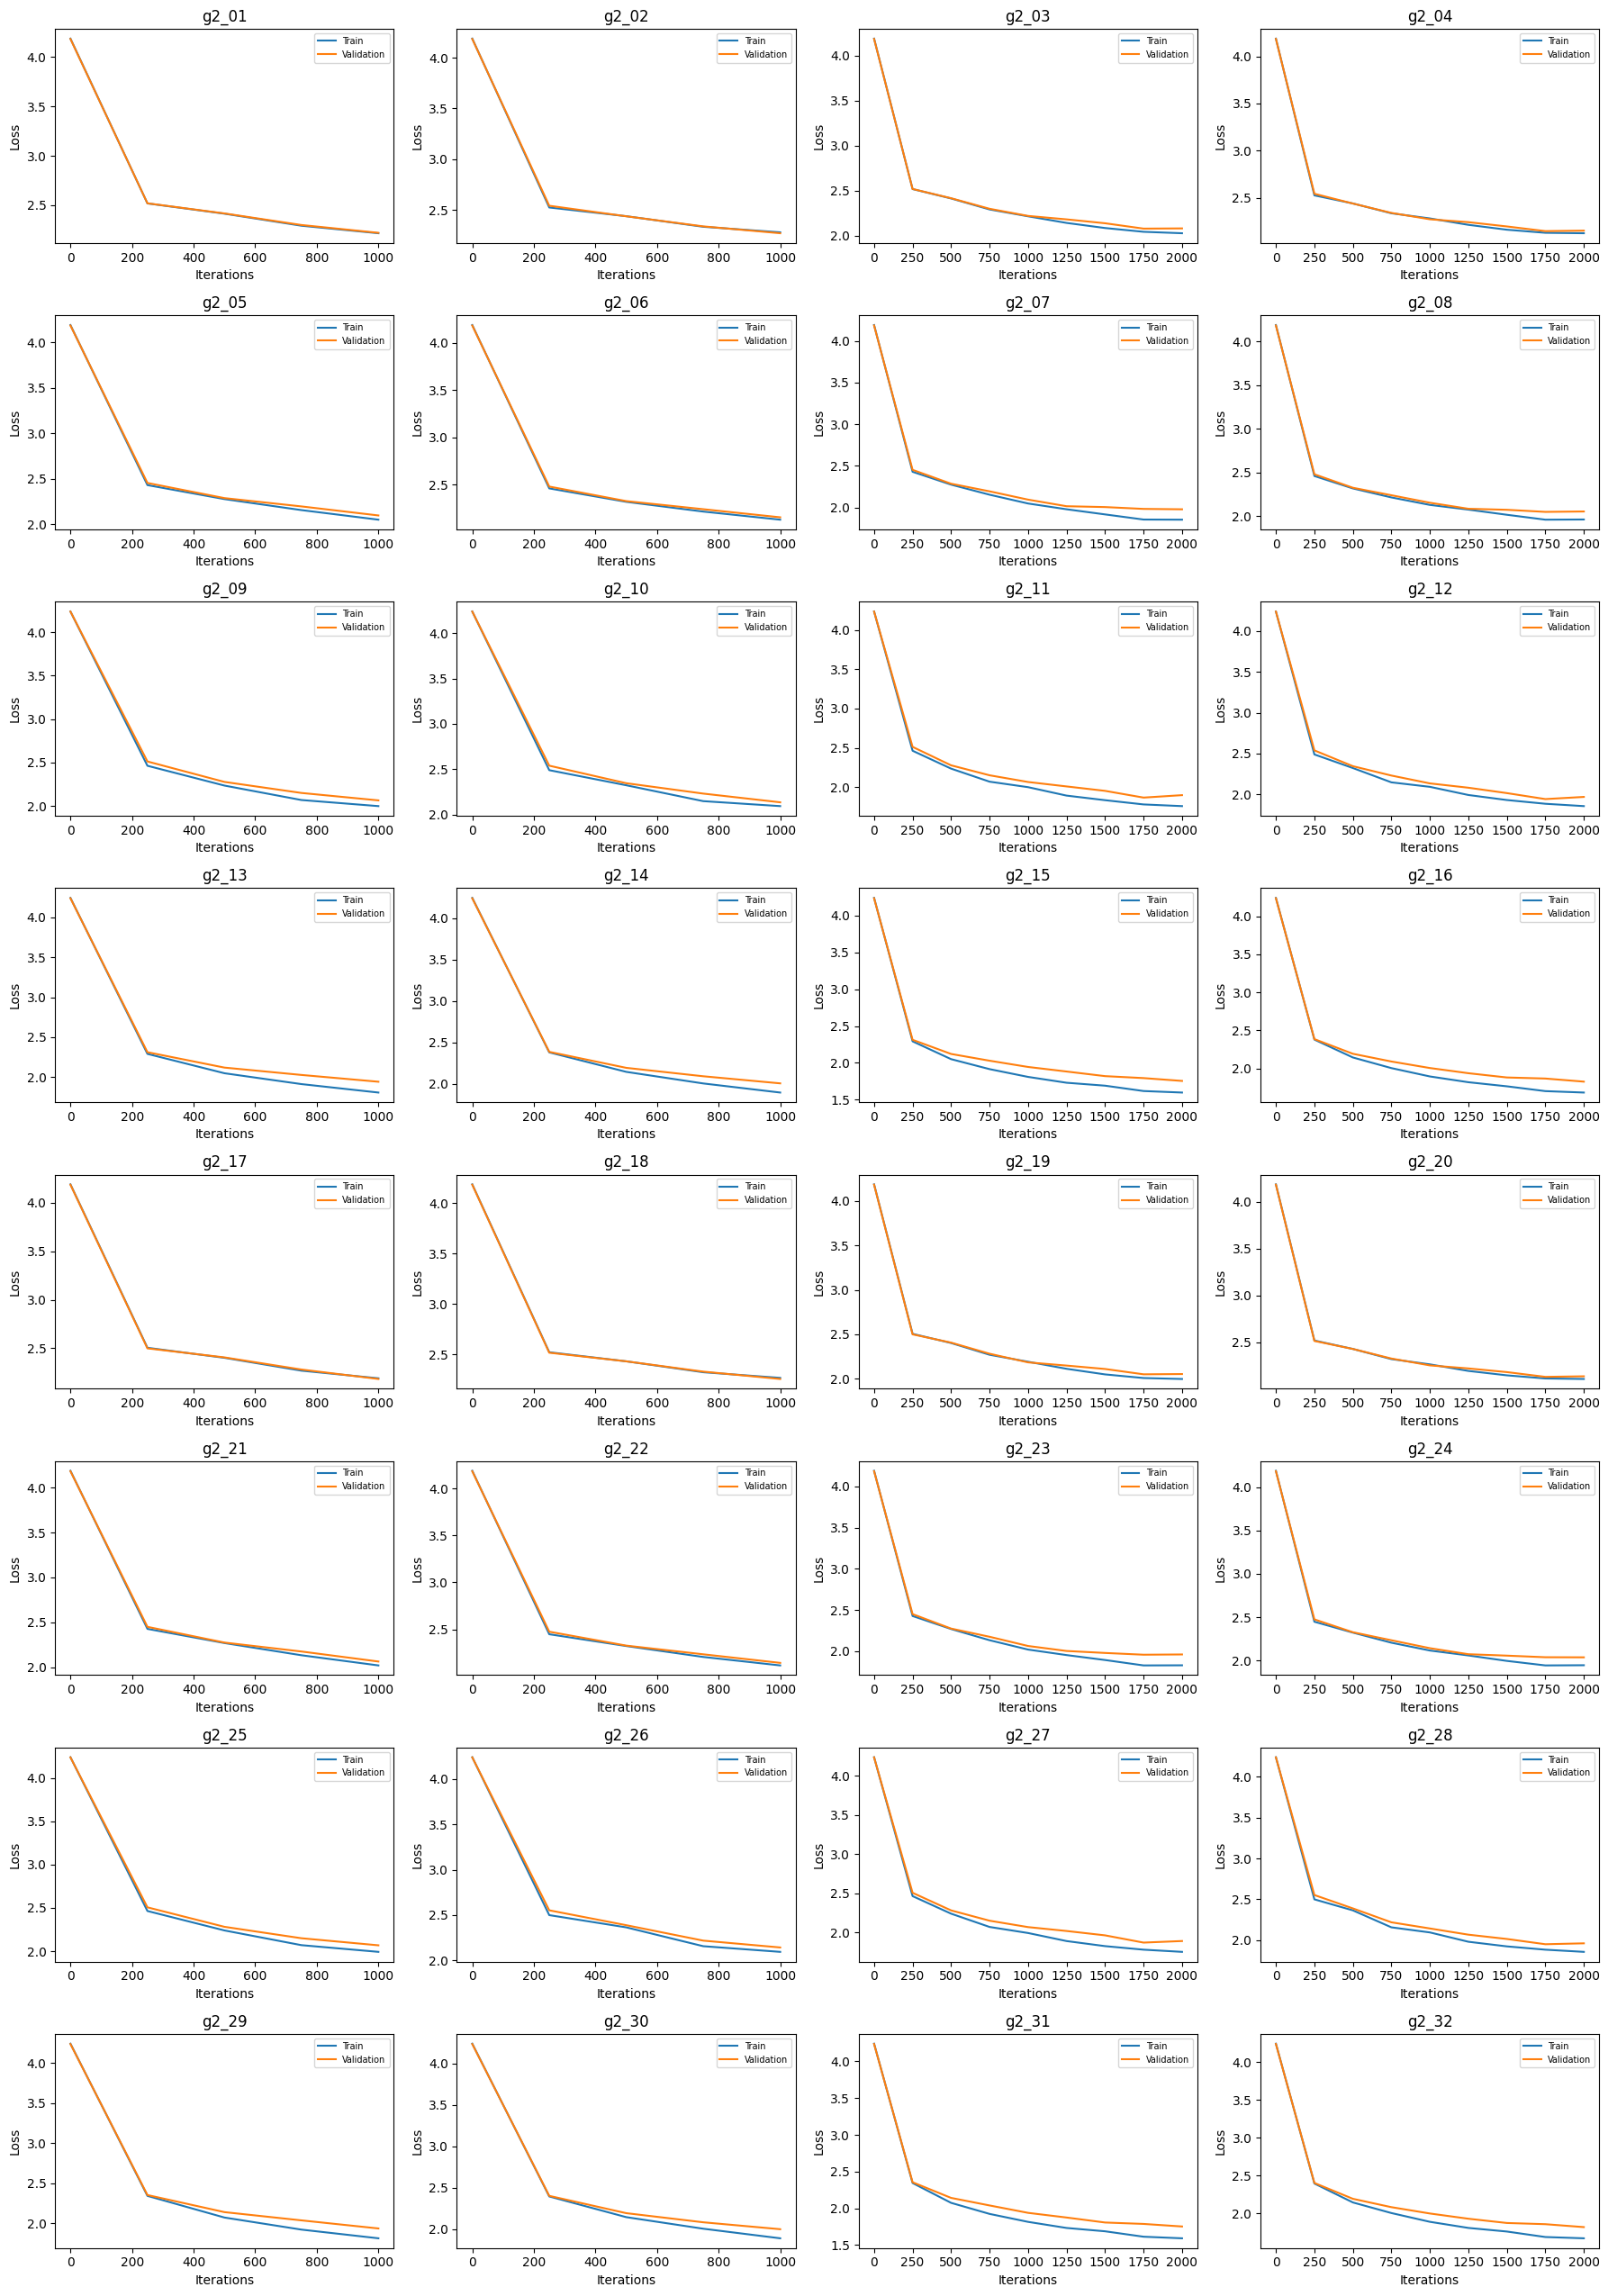

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("results/member2/results.csv")

import math
rows = math.ceil(len(df) / 4)
fig, axes = plt.subplots(rows, 4, figsize=(18, max(4, rows * 3.2)))

for ax, run in zip(axes.flat, df["run"]):
    history = pd.read_csv(
        f"results/member2/{run}/loss_history.csv"
    )

    ax.plot(history["step"], history["train_loss"], label="Train")
    ax.plot(history["step"], history["val_loss"], label="Validation")
    ax.set_title(run)
    ax.set_xlabel("Iterations")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=7)

for ax in axes.flat[len(df):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("results/member2/loss_curves.png", dpi=150)
plt.show()


 n_head
n_head
4    2.0373
8    2.0251
Name: val_loss, dtype: float64

 n_embd
n_embd
128    2.1147
256    1.9476
Name: val_loss, dtype: float64

 batch_size
batch_size
8     2.0928
16    1.9695
Name: val_loss, dtype: float64

 max_iters
max_iters
1000    2.1049
2000    1.9574
Name: val_loss, dtype: float64

 dropout
dropout
0.1    1.9964
0.2    2.0660
Name: val_loss, dtype: float64


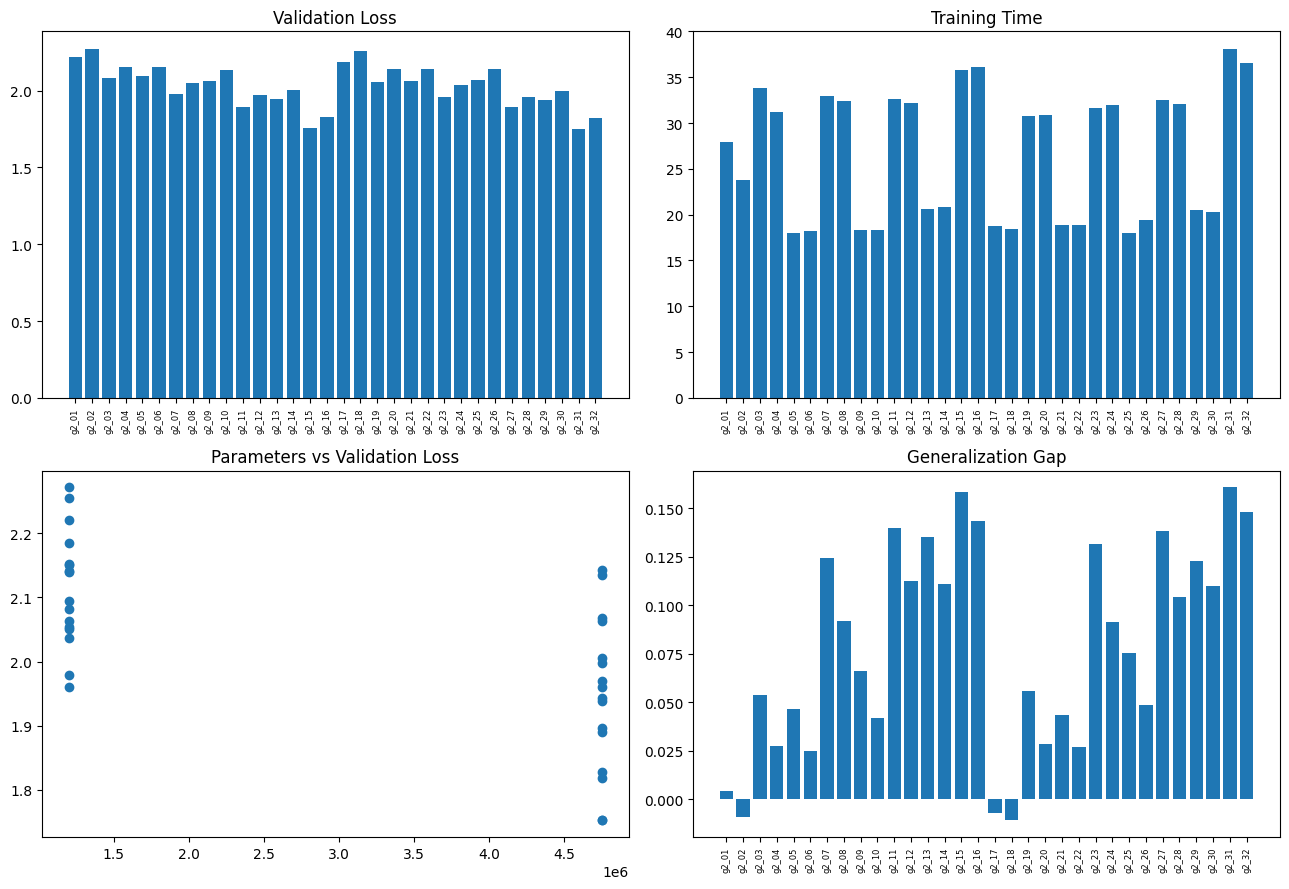

In [25]:
df["loss_gap"] = df["val_loss"] - df["train_loss"]

for parameter in [
    "n_head", "n_embd", "batch_size",
    "max_iters", "dropout"
]:
    print("\n", parameter)
    print(df.groupby(parameter)["val_loss"].mean().round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].bar(df["run"], df["val_loss"])
axes[0, 0].set_title("Validation Loss")

axes[0, 1].bar(df["run"], df["time_seconds"])
axes[0, 1].set_title("Training Time")

axes[1, 0].scatter(df["parameters"], df["val_loss"])
axes[1, 0].set_title("Parameters vs Validation Loss")

axes[1, 1].bar(df["run"], df["loss_gap"])
axes[1, 1].set_title("Generalization Gap")

for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.tick_params(axis="x", rotation=90, labelsize=6)

plt.tight_layout()
plt.savefig("results/member2/comparisons.png", dpi=150)
plt.show()

In [26]:
import pandas as pd
from pathlib import Path

df = pd.read_csv("results/member2/results.csv")

best = df.loc[df["val_loss"].idxmin()]
worst = df.loc[df["val_loss"].idxmax()]

print("BEST MODEL:")
display(best.to_frame().T)
print(Path(f"results/member2/{best['run']}/sample.txt").read_text())

print("\nWORST MODEL:")
display(worst.to_frame().T)
print(Path(f"results/member2/{worst['run']}/sample.txt").read_text())

BEST MODEL:


,run,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
30,g2_31,64,6,8,256,16,2000,0.1,1.5913,1.7522,38.1,4754944,179.05957


Overriding: device = cuda
Overriding: compile = False
Overriding: out_dir = results/member2/g2_31
Overriding: start = ROMEO:
Overriding: num_samples = 1
Overriding: max_new_tokens = 200
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: seed = 1337
number of parameters: 4.74M
Loading meta from data/shakespeare_char/meta.pkl...
ROMEO:
You before will and is the servaited bube to take Our some?

Takes:
Whith foul him to behed lady, ever you had for a will our
to them of it heart my would butes it ensengein lattent,
What the dest no
---------------


WORST MODEL:


,run,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
1,g2_02,64,6,4,128,8,1000,0.2,2.2809,2.2718,23.78,1197824,56.743164


Overriding: device = cuda
Overriding: compile = False
Overriding: out_dir = results/member2/g2_02
Overriding: start = ROMEO:
Overriding: num_samples = 1
Overriding: max_new_tokens = 200
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: seed = 1337
number of parameters: 1.19M
Loading meta from data/shakespeare_char/meta.pkl...
ROMEO:
Al the Ror we wild to on, be mad and bube ale.



OSE SMANCELUNGOX:
Whith fous he he thar dilas ane ar ceamy.


DEROYINGIING:
Youst, tof is he me my welill, at miree senghin;
Sit mail ove spand ben p
---------------



In [27]:
from pathlib import Path

base = Path("results/member2")

print("Results CSV:", (base / "results.csv").exists())
print("Loss curves:", (base / "loss_curves.png").exists())
print("Comparison graphs:", (base / "comparisons.png").exists())

samples = list(base.glob("g2_*/sample.txt"))
histories = list(base.glob("g2_*/loss_history.csv"))

print("Generated samples:", len(samples), "/ 32")
print("Loss histories:", len(histories), "/ 32")

Results CSV: True
Loss curves: True
Comparison graphs: True
Generated samples: 32 / 32
Loss histories: 32 / 32


## Saved results

I exported the results to a ZIP file with the CSV, training logs, loss histories, generated text, and graphs. I left out the model checkpoint files to keep the ZIP smaller.

In [28]:
from pathlib import Path
import zipfile

base = Path('results/member2')
zip_path = Path('/content/Group7_Member2_Results.zip')
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for p in base.rglob('*'):
        if p.is_file() and p.name != 'ckpt.pt':
            zf.write(p, arcname=p.as_posix())
print('Created:', zip_path, 'size:', round(zip_path.stat().st_size / (1024**2), 2), 'MB')
from google.colab import files
files.download(str(zip_path))

Created: /content/Group7_Member2_Results.zip size: 0.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Results summary

All 32 experiments completed. The best validation loss was 1.7522 from g2_31, which used 8 attention heads, 256 embedding dimensions, batch size 16, 2,000 iterations, and 0.1 dropout. Its training loss was 1.5913. The highest validation loss was 2.2718 from g2_02, which used 4 heads, 128 embedding dimensions, batch size 8, 1,000 iterations, and 0.2 dropout.

Based on the averages, increasing the embedding size from 128 to 256 and training for 2,000 instead of 1,000 iterations both helped lower validation loss. Batch size 16 did better than 8, and dropout 0.1 did better than 0.2. Changing from 4 to 8 attention heads made a much smaller difference.

The sample from g2_31 has some Shakespeare-like wording and dialogue formatting, but it still makes up words and doesn't always form clear sentences. So the lower loss helped, but the generated text still isn't very convincing. These results are from single runs, and the notebook uses sampled validation loss. Member 1 used a different full-validation calculation, so those loss numbers shouldn't be compared directly.
